# Telemanom data inspection

Goal: understand telemetry array structure and annotation alignment
before constructing features or training models.

In [21]:
from pathlib import Path

Path.cwd()

WindowsPath('c:/dev/satmon/satmon/notebooks')

In [22]:
import numpy as np

path = Path("../data/raw/archive/data/data/test/P-1.npy")
values = np.load(path, allow_pickle=False)

print("Shape:", values.shape)
print("Data Type:", values.dtype)
print("First five telemetry values:", values[:5, 0])

Shape: (8505, 25)
Data Type: float64
First five telemetry values: [-0.69516194 -0.68570386 -0.72571851 -0.76136787 -0.74536192]


In [23]:
signal = values[:, 0]

print("Signal shape:", signal.shape)
print("All values finite:", np.isfinite(signal).all())
print("Minimum:", signal.min())
print("Maximum:", signal.max())

Signal shape: (8505,)
All values finite: True
Minimum: -1.0
Maximum: 1.0000000000000004


In [24]:
import pandas as pd

annotations = pd.read_csv("../data/raw/labeled_anomalies.csv")
p1_annotations = annotations.loc[annotations["chan_id"] == "P-1"]

p1_annotations

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505


In [40]:
from satmon.data import parse_intervals

intervals = parse_intervals(
    text=p1_annotations.iloc[0]["anomaly_sequences"],
    n_samples=len(signal),
)

print(intervals)
print(type(intervals))

[(2149, 2349), (4536, 4844), (3539, 3779)]
<class 'list'>


In [26]:
for start, end in intervals:
    if 0 <= start <= end < len(signal):
        print(f"({start}, {end})")
    else:
        print("failure")

(2149, 2349)
(4536, 4844)
(3539, 3779)


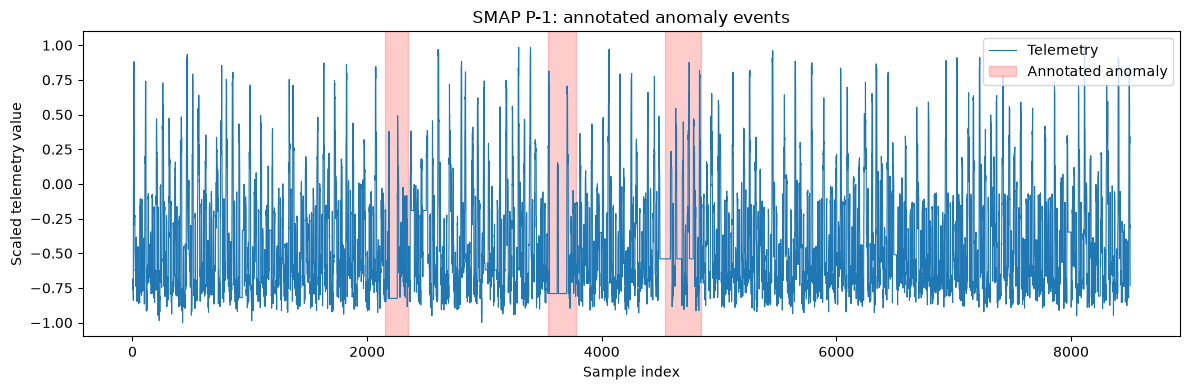

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(signal, linewidth=0.8, label="Telemetry")

for i, (start, end) in enumerate(sorted(intervals)):
    ax.axvspan(
        start,
        end,
        color="red",
        alpha=0.2,
        label="Annotated anomaly" if i == 0 else None,
    )

ax.set(
    xlabel="Sample index",
    ylabel="Scaled telemetry value",
    title="SMAP P-1: annotated anomaly events",
)
ax.legend()
fig.tight_layout()
plt.show()

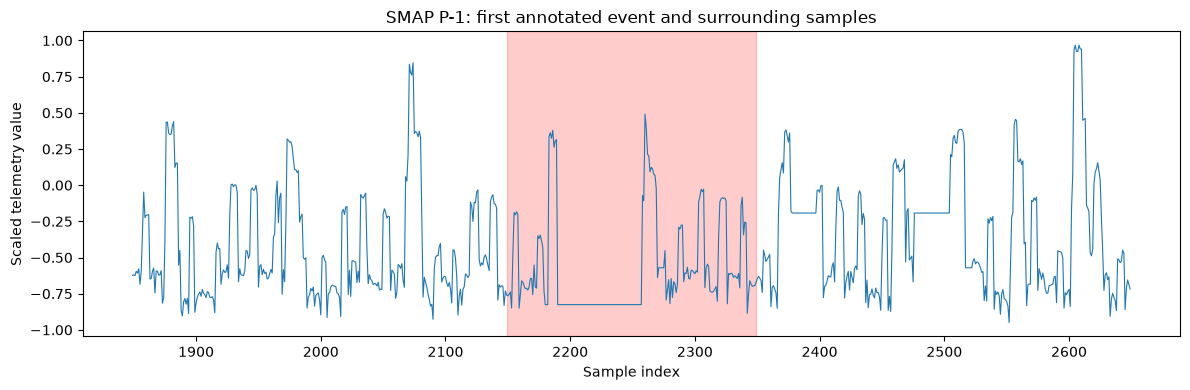

In [28]:
fig, ax = plt.subplots(figsize=(12, 4))

start, end = sorted(intervals)[0]
left = max(0, start - 300)
right = min(len(signal), end + 301)

ax.plot(range(left, right), signal[left:right], linewidth=0.8)
ax.axvspan(start, end, color="red", alpha=0.2)

ax.set(
    xlabel="Sample index",
    ylabel="Scaled telemetry value",
    title="SMAP P-1: first annotated event and surrounding samples",
)
fig.tight_layout()
plt.show()

Within P-1’s first annotated event, a nearly constant segment appears around samples 2190–2260. Its magnitude is not unique to the event. This motivates investigating local variability alongside telemetry value; it does not establish the anomaly’s physical cause.

In [29]:
print("Annotation rows:", len(annotations))
print("Unique channel IDs:", annotations["chan_id"].nunique())

print("\nUnique channels by spacecraft:")
print(annotations.groupby("spacecraft")["chan_id"].nunique())

duplicate_rows = annotations.loc[
    annotations.duplicated("chan_id", keep=False)
]

print("\nRepeated channel IDs:")
display(duplicate_rows)

Annotation rows: 82
Unique channel IDs: 81

Unique channels by spacecraft:
spacecraft
MSL     27
SMAP    54
Name: chan_id, dtype: int64

Repeated channel IDs:


,chan_id,spacecraft,anomaly_sequences,class,num_values
17,P-2,SMAP,"[[5350, 6575]]",[point],8209
51,P-2,SMAP,"[[5300, 6420]]",[point],8209


In [30]:
raw_dir = Path("../data/raw")

for csv_path in raw_dir.rglob("labeled_anomalies.csv"):
    print(csv_path)

..\data\raw\labeled_anomalies.csv
..\data\raw\archive\labeled_anomalies.csv


In [31]:
archive_annotations = pd.read_csv(
    "../data/raw/archive/labeled_anomalies.csv"
)

print("Tables identical:", annotations.equals(archive_annotations))
print("Archive rows:", len(archive_annotations))
print("Archive unique channels:", archive_annotations["chan_id"].nunique())

display(
    archive_annotations.loc[
        archive_annotations["chan_id"] == "P-2"
    ]
)

Tables identical: True
Archive rows: 82
Archive unique channels: 81


,chan_id,spacecraft,anomaly_sequences,class,num_values
17,P-2,SMAP,"[[5350, 6575]]",[point],8209
51,P-2,SMAP,"[[5300, 6420]]",[point],8209


Both annotation copies are identical. P-2 has two overlapping but different annotated intervals for the same sequence. We exclude this channel from the primary experiment because its event definition is ambiguous, retaining the original annotations unchanged.

In [32]:
eligible_annotations = annotations.loc[
    annotations["chan_id"] != "P-2"
].copy()

assert eligible_annotations["chan_id"].is_unique

print("Eligible channels:", len(eligible_annotations))
print(eligible_annotations.groupby("spacecraft")["chan_id"].nunique())

Eligible channels: 80
spacecraft
MSL     27
SMAP    53
Name: chan_id, dtype: int64


In [33]:
test_dir = Path("../data/raw/archive/data/data/test")

missing_channels = []

for channel_id in eligible_annotations["chan_id"]:
    channel_path = test_dir / f"{channel_id}.npy"

    if not channel_path.is_file():
        missing_channels.append(channel_id)

print("Missing test files:", missing_channels)

Missing test files: []


In [34]:
from sklearn.model_selection import train_test_split

# P-1 is reserved for training because it informed feature exploration.
remaining = eligible_annotations.loc[
    eligible_annotations["chan_id"] != "P-1"
].copy()

train_pool, holdout = train_test_split(
    remaining,
    test_size=32,
    random_state=42,
    stratify=remaining["spacecraft"],
)

validation, test = train_test_split(
    holdout,
    test_size=16,
    random_state=42,
    stratify=holdout["spacecraft"],
)

train = pd.concat([
    train_pool,
    eligible_annotations.loc[eligible_annotations["chan_id"] == "P-1"],
])

for name, table in [
    ("train", train),
    ("validation", validation),
    ("test", test),
]:
    print(name, len(table))
    print(table.groupby("spacecraft").size())

train 48
spacecraft
MSL     16
SMAP    32
dtype: int64
validation 16
spacecraft
MSL      5
SMAP    11
dtype: int64
test 16
spacecraft
MSL      6
SMAP    10
dtype: int64


In [35]:
train_ids = set(train["chan_id"])
validation_ids = set(validation["chan_id"])
test_ids = set(test["chan_id"])

assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)

assert train_ids | validation_ids | test_ids == set(
    eligible_annotations["chan_id"]
)

assert "P-1" in train_ids
assert "P-2" not in train_ids | validation_ids | test_ids

print("Split checks passed.")

Split checks passed.


In [36]:
import hashlib
import json

split_record = {
    "seed": 42,
    "annotation_sha256": hashlib.sha256(
        Path("../data/raw/labeled_anomalies.csv").read_bytes()
    ).hexdigest(),
    "excluded_channels": {
        "P-2": "Conflicting overlapping annotations in duplicate rows."
    },
    "reserved_training_channels": {
        "P-1": "Inspected before splitting and used to motivate features."
    },
    "train": sorted(train_ids),
    "validation": sorted(validation_ids),
    "test": sorted(test_ids),
}

split_path = Path("../splits/channels.json")
split_path.parent.mkdir(parents=True, exist_ok=True)

# Refuse to overwrite an existing split with different assignments.
if split_path.exists():
    saved_record = json.loads(split_path.read_text(encoding="utf-8"))
    assert saved_record == split_record, "Existing split differs; investigate."
else:
    split_path.write_text(
        json.dumps(split_record, indent=2) + "\n",
        encoding="utf-8",
    )

print("Saved and verified:", split_path.resolve())

Saved and verified: C:\dev\satmon\satmon\splits\channels.json


In [37]:
annotation_issues = []

for _, row in train.iterrows():
    events = parse_intervals(
        row["anomaly_sequences"],
        int(row["num_values"]),
    )

    event_types = [
        item.strip()
        for item in row["class"].strip("[]").split(",")
        if item.strip()
    ]

    if len(events) != len(event_types):
        annotation_issues.append(
            (row["chan_id"], "Event/type count mismatch")
        )

    if any(t not in {"point", "contextual"} for t in event_types):
        annotation_issues.append(
            (row["chan_id"], "Unknown event type")
        )

    ordered_events = sorted(events)

    for previous, current in zip(ordered_events, ordered_events[1:]):
        if current[0] <= previous[1]:
            annotation_issues.append(
                (row["chan_id"], "Overlapping intervals")
            )

print("Annotation issues:", annotation_issues)

Annotation issues: []


In [38]:
import sys

print(sys.executable)

c:\dev\satmon\satmon\.venv\Scripts\python.exe


In [41]:
import importlib
import satmon.data
import satmon.features

importlib.reload(satmon.data)
importlib.reload(satmon.features)

from satmon.data import make_sample_labels, make_window_labels
from satmon.features import make_basic_features

In [ ]:
from satmon.data import make_sample_labels, make_window_labels
from satmon.features import make_basic_features

example_signal = np.array([2.0, 3.0, 3.0, 1.0, 2.0, 2.0, 2.0])

sample_labels = make_sample_labels(
    len(example_signal),
    [(2, 3)],
)

prediction_indices, window_labels = make_window_labels(
    sample_labels,
    window_size=3,
)

features = make_basic_features(example_signal)

examples = features.loc[prediction_indices].copy()
examples["label"] = window_labels

display(examples)

,value,delta,label
sample_index,,,
2,3.0,0.0,1
3,1.0,-2.0,1
4,2.0,1.0,1
5,2.0,0.0,1
